In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [37]:
calls = pd.read_csv("../data/calls.csv")

sms = pd.read_csv("../data/sms.csv")

bt = pd.read_csv(
    "../data/bt_symmetric.csv",
    comment="#",
    header=None,
    names=["timestamp", "user_a", "user_b", "rssi"]
)

friends = pd.read_csv(
    "../data/fb_friends.csv",
    comment="#",
    header=None,
    names=["user_a", "user_b"]
)

genders = pd.read_csv(
    "../data/genders.csv",
    comment="#",
    header=None,
    names=["user", "female"]
)


In [38]:
print("CALLS")
display(calls.head())

print("SMS")
display(sms.head())

print("BLUETOOTH")
display(bt.head())

print("FACEBOOK FRIENDS")
display(friends.head())

print("GENDERS")
display(genders.head())

CALLS


,timestamp,caller,callee,duration
0,184,300,301,121
1,3920,512,299,670
2,5623,301,300,504
3,9252,401,457,-1
4,15466,512,0,5


SMS


,timestamp,sender,recipient
0,18,370,512
1,37,512,370
2,126,370,512
3,134,0,512
4,312,137,136


BLUETOOTH


,timestamp,user_a,user_b,rssi
0,0,0,-1,0
1,0,1,-1,0
2,0,2,-1,0
3,0,3,-2,-88
4,0,5,-1,0


FACEBOOK FRIENDS


,user_a,user_b
0,0,512
1,0,263
2,0,525
3,0,285
4,0,543


GENDERS


,user,female
0,0,0
1,2,0
2,3,0
3,4,0
4,5,0


In [39]:
print("Number of rows:")
print("Calls:", len(calls))
print("SMS:", len(sms))
print("Bluetooth:", len(bt))
print("Facebook friendships:", len(friends))
print("Gender records:", len(genders))


Number of rows:
Calls: 3600
SMS: 24333
Bluetooth: 5474289
Facebook friendships: 6429
Gender records: 787


In [40]:
print("\nCALLS")
calls.info()

print("\nSMS")
sms.info()

print("\nBLUETOOTH")
bt.info()

print("\nFACEBOOK FRIENDS")
friends.info()

print("\nGENDERS")
genders.info()



CALLS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   timestamp  3600 non-null   int64
 1   caller     3600 non-null   int64
 2   callee     3600 non-null   int64
 3   duration   3600 non-null   int64
dtypes: int64(4)
memory usage: 112.6 KB

SMS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24333 entries, 0 to 24332
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   timestamp  24333 non-null  int64
 1   sender     24333 non-null  int64
 2   recipient  24333 non-null  int64
dtypes: int64(3)
memory usage: 570.4 KB

BLUETOOTH
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5474289 entries, 0 to 5474288
Data columns (total 4 columns):
 #   Column     Dtype
---  ------     -----
 0   timestamp  int64
 1   user_a     int64
 2   user_b     int64
 3   rssi       int64
dtypes: int64(4)
memo

In [41]:
print("Missing values in calls:")
display(calls.isna().sum())

print("Missing values in SMS:")
display(sms.isna().sum())

print("Missing values in Bluetooth:")
display(bt.isna().sum())

print("Missing values in Facebook friendships:")
display(friends.isna().sum())

print("Missing values in genders:")
display(genders.isna().sum())



Missing values in calls:


timestamp    0
caller       0
callee       0
duration     0
dtype: int64

Missing values in SMS:


timestamp    0
sender       0
recipient    0
dtype: int64

Missing values in Bluetooth:


timestamp    0
user_a       0
user_b       0
rssi         0
dtype: int64

Missing values in Facebook friendships:


user_a    0
user_b    0
dtype: int64

Missing values in genders:


user      0
female    0
dtype: int64

In [42]:
print("Duplicate rows:")
print("Calls:", calls.duplicated().sum())
print("SMS:", sms.duplicated().sum())
print("Bluetooth:", bt.duplicated().sum())
print("Facebook friendships:", friends.duplicated().sum())
print("Genders:", genders.duplicated().sum())

Duplicate rows:
Calls: 0
SMS: 21
Bluetooth: 0
Facebook friendships: 0
Genders: 0


In [43]:
print("Calls:")
display(calls.describe())

print("SMS:")
display(sms.describe())

print("Bluetooth:")
display(bt.describe())



Calls:


,timestamp,caller,callee,duration
count,3.600000e+03,3600.000000,3600.000000,3600.000000
mean,1.281670e+06,349.840833,354.581111,56.790833
std,6.662889e+05,226.328594,221.136143,176.862896
min,1.840000e+02,0.000000,0.000000,-1.000000
25%,7.501832e+05,143.000000,163.750000,0.000000
50%,1.250542e+06,335.000000,354.000000,10.000000
75%,1.819620e+06,560.000000,552.000000,50.000000
max,2.416399e+06,846.000000,845.000000,5138.000000


SMS:


,timestamp,sender,recipient
count,2.433300e+04,24333.000000,24333.000000
mean,1.161996e+06,335.711421,334.693996
std,6.883014e+05,212.399709,213.045789
min,1.800000e+01,0.000000,0.000000
25%,5.744050e+05,152.000000,149.000000
50%,1.080494e+06,296.000000,296.000000
75%,1.729376e+06,531.000000,540.000000
max,2.418982e+06,846.000000,846.000000


Bluetooth:


,timestamp,user_a,user_b,rssi
count,5.474289e+06,5.474289e+06,5.474289e+06,5.474289e+06
mean,1.217629e+06,3.791028e+02,9.568739e+01,-4.994969e+01
std,6.786570e+05,1.947784e+02,1.495550e+02,4.207211e+01
min,0.000000e+00,0.000000e+00,-2.000000e+00,-1.070000e+02
25%,6.762000e+05,2.210000e+02,-1.000000e+00,-8.800000e+01
50%,1.206000e+06,3.940000e+02,-1.000000e+00,-7.400000e+01
75%,1.801500e+06,5.430000e+02,1.660000e+02,0.000000e+00
max,2.418900e+06,8.450000e+02,7.040000e+02,2.000000e+01


In [44]:
call_users = set(calls["caller"]).union(set(calls["callee"]))
sms_users = set(sms["sender"]).union(set(sms["recipient"]))

print("Unique users in calls:", len(call_users))
print("Unique users in SMS:", len(sms_users))
print("Unique users in gender data:", genders["user"].nunique())

Unique users in calls: 536
Unique users in SMS: 568
Unique users in gender data: 787


In [45]:
calls["call_status"] = np.where(
    calls["duration"] == -1,
    "Missed",
    "Answered"
)

display(calls.head())

,timestamp,caller,callee,duration,call_status
0,184,300,301,121,Answered
1,3920,512,299,670,Answered
2,5623,301,300,504,Answered
3,9252,401,457,-1,Missed
4,15466,512,0,5,Answered


In [46]:
call_status_counts = calls["call_status"].value_counts()

display(call_status_counts)

print("\nPercentages:")
display(
    calls["call_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


call_status
Answered    3234
Missed       366
Name: count, dtype: int64


Percentages:


call_status
Answered    89.83
Missed      10.17
Name: proportion, dtype: float64

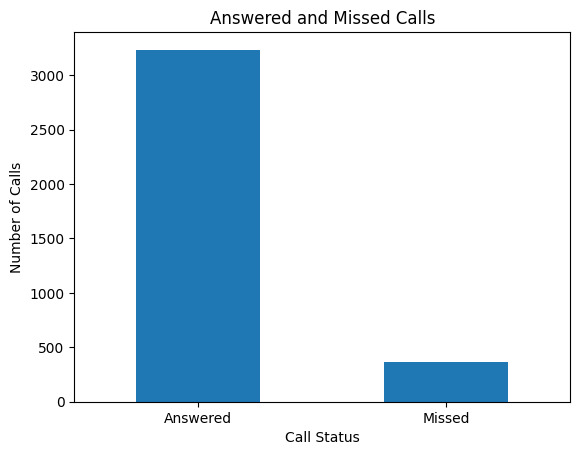

In [47]:
call_status_counts.plot(kind="bar")

plt.title("Answered and Missed Calls")
plt.xlabel("Call Status")
plt.ylabel("Number of Calls")
plt.xticks(rotation=0)
plt.show()

In [48]:

answered_calls = calls[calls["duration"] >= 0].copy()

display(answered_calls["duration"].describe())

count    3234.000000
mean       63.331169
std       185.474508
min         0.000000
25%         2.000000
50%        16.000000
75%        57.000000
max      5138.000000
Name: duration, dtype: float64

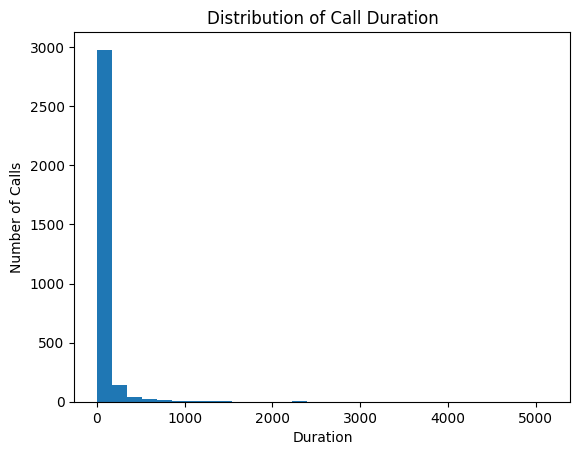

In [49]:
plt.hist(answered_calls["duration"], bins=30)

plt.title("Distribution of Call Duration")
plt.xlabel("Duration")
plt.ylabel("Number of Calls")
plt.show()



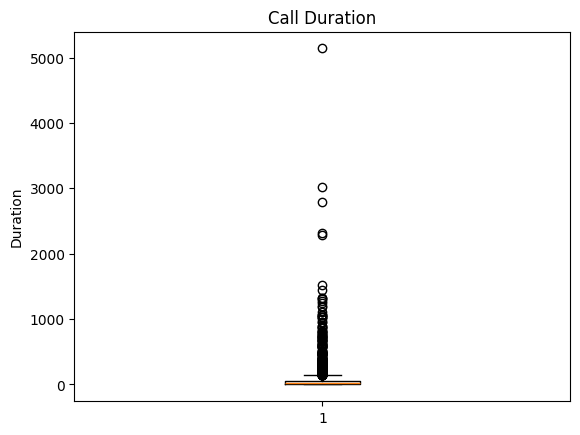

In [50]:
plt.boxplot(answered_calls["duration"])

plt.title("Call Duration")
plt.ylabel("Duration")
plt.show()



In [51]:
print("Minimum duration:")
print(calls["duration"].min())

print("\nMaximum duration:")
print(calls["duration"].max())

print("\nCalls with duration below -1:")
display(calls[calls["duration"] < -1])

print("\nAnswered calls with duration 0:")
display(calls[calls["duration"] == 0])


Minimum duration:
-1

Maximum duration:
5138

Calls with duration below -1:


,timestamp,caller,callee,duration,call_status



Answered calls with duration 0:


,timestamp,caller,callee,duration,call_status
12,38151,584,582,0,Answered
17,40307,480,210,0,Answered
18,46698,267,269,0,Answered
51,65878,12,13,0,Answered
57,69794,12,13,0,Answered
...,...,...,...,...,...
3505,2324367,534,360,0,Answered
3514,2330989,354,666,0,Answered
3525,2366001,558,162,0,Answered
3536,2371597,661,683,0,Answered


In [52]:
calls_per_caller = (
    calls.groupby("caller")
    .size()
    .sort_values(ascending=False)
)

display(calls_per_caller.head(20))

caller
289    94
21     68
578    67
221    54
37     51
47     44
405    42
424    41
49     39
678    38
90     38
91     38
48     37
560    36
300    35
263    33
623    32
356    31
301    31
688    31
dtype: int64

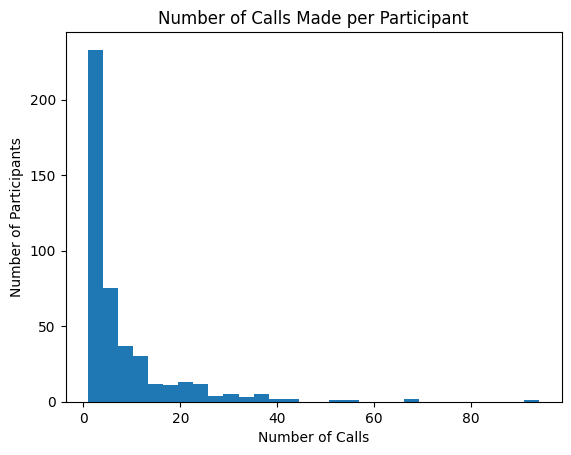

In [53]:
plt.hist(calls_per_caller, bins=30)

plt.title("Number of Calls Made per Participant")
plt.xlabel("Number of Calls")
plt.ylabel("Number of Participants")
plt.show()

In [54]:
calls_per_receiver = (
    calls.groupby("callee")
    .size()
    .sort_values(ascending=False)
)

display(calls_per_receiver.head(20))



callee
578    101
20      68
301     55
560     52
49      52
405     52
90      47
470     47
289     42
47      35
681     34
449     33
651     32
210     31
495     31
401     28
420     28
288     28
622     28
91      27
dtype: int64

In [55]:
calls["answered"] = (calls["duration"] != -1).astype(int)

receiver_answer_rate = (
    calls.groupby("callee")["answered"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_calls_received",
        "mean": "answer_rate"
    })
)

display(receiver_answer_rate.head())

,number_of_calls_received,answer_rate
callee,,
0,6,1.000000
3,10,0.900000
4,20,1.000000
5,5,0.400000
6,6,0.666667


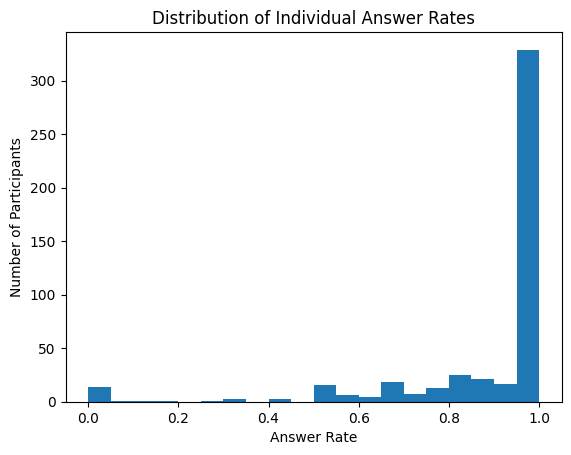

In [56]:
plt.hist(receiver_answer_rate["answer_rate"], bins=20)

plt.title("Distribution of Individual Answer Rates")
plt.xlabel("Answer Rate")
plt.ylabel("Number of Participants")
plt.show()

In [57]:
print("Number of SMS messages:", len(sms))
print("Unique SMS senders:", sms["sender"].nunique())
print("Unique SMS recipients:", sms["recipient"].nunique())

display(sms.describe())



Number of SMS messages: 24333
Unique SMS senders: 555
Unique SMS recipients: 555


,timestamp,sender,recipient
count,2.433300e+04,24333.000000,24333.000000
mean,1.161996e+06,335.711421,334.693996
std,6.883014e+05,212.399709,213.045789
min,1.800000e+01,0.000000,0.000000
25%,5.744050e+05,152.000000,149.000000
50%,1.080494e+06,296.000000,296.000000
75%,1.729376e+06,531.000000,540.000000
max,2.418982e+06,846.000000,846.000000


In [58]:
sms_per_sender = (
    sms.groupby("sender")
    .size()
    .sort_values(ascending=False)
)

display(sms_per_sender.head(20))

sender
617    1585
279    1448
176    1107
578    1003
481     797
21      486
91      428
90      395
512     357
296     349
299     335
137     321
136     318
20      313
274     265
632     239
218     237
36      215
93      188
335     178
dtype: int64

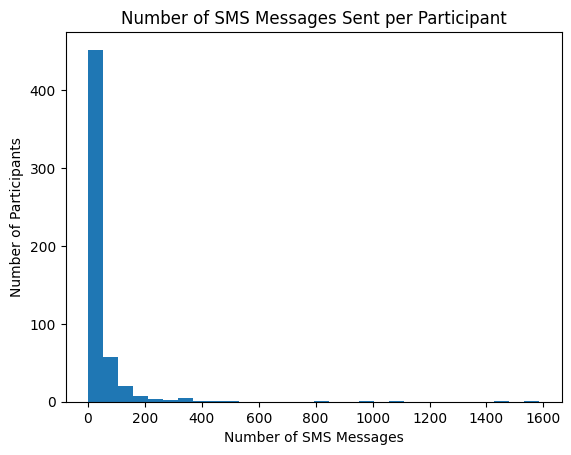

In [59]:
plt.hist(sms_per_sender, bins=30)

plt.title("Number of SMS Messages Sent per Participant")
plt.xlabel("Number of SMS Messages")
plt.ylabel("Number of Participants")
plt.show()

In [60]:
print("Bluetooth rows:", len(bt))

print("\nEmpty scans (user_b = -1):")
print((bt["user_b"] == -1).sum())

print("\nDevices outside the experiment (user_b = -2):")
print((bt["user_b"] == -2).sum())

print("\nParticipant-to-participant observations:")
print((bt["user_b"] >= 0).sum())

Bluetooth rows: 5474289

Empty scans (user_b = -1):
2220136

Devices outside the experiment (user_b = -2):
827874

Participant-to-participant observations:
2426279


In [61]:
bt_participants = bt[bt["user_b"] >= 0].copy()

display(bt_participants["rssi"].describe())




count    2.426279e+06
mean    -8.466674e+01
std      1.014296e+01
min     -1.000000e+02
25%     -9.200000e+01
50%     -8.600000e+01
75%     -7.900000e+01
max      2.000000e+01
Name: rssi, dtype: float64

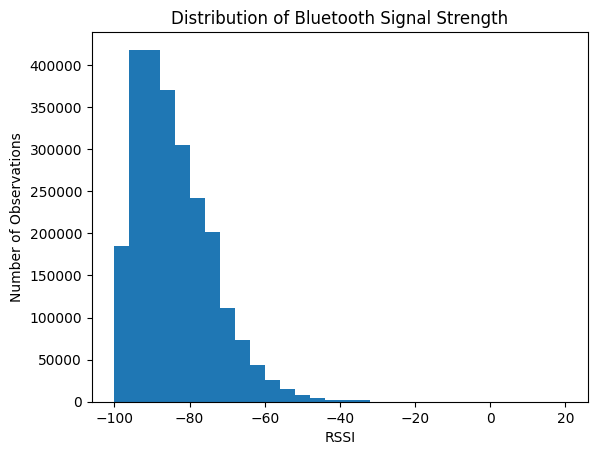

In [62]:
plt.hist(bt_participants["rssi"], bins=30)

plt.title("Distribution of Bluetooth Signal Strength")
plt.xlabel("RSSI")
plt.ylabel("Number of Observations")
plt.show()

In [63]:
print("Number of Facebook friendship links:", len(friends))
print("Unique user A:", friends["user_a"].nunique())
print("Unique user B:", friends["user_b"].nunique())

display(friends.head())

Number of Facebook friendship links: 6429
Unique user A: 668
Unique user B: 733


,user_a,user_b
0,0,512
1,0,263
2,0,525
3,0,285
4,0,543


In [64]:
print("Number of gender records:", len(genders))

display(genders["female"].value_counts())

display(
    genders["female"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Number of gender records: 787


female
0    614
1    173
Name: count, dtype: int64

female
0    78.02
1    21.98
Name: proportion, dtype: float64

In [65]:
print("Call timestamps:")
print("Min:", calls["timestamp"].min())
print("Max:", calls["timestamp"].max())

print("\nSMS timestamps:")
print("Min:", sms["timestamp"].min())
print("Max:", sms["timestamp"].max())

print("\nBluetooth timestamps:")
print("Min:", bt["timestamp"].min())
print("Max:", bt["timestamp"].max())

Call timestamps:
Min: 184
Max: 2416399

SMS timestamps:
Min: 18
Max: 2418982

Bluetooth timestamps:
Min: 0
Max: 2418900


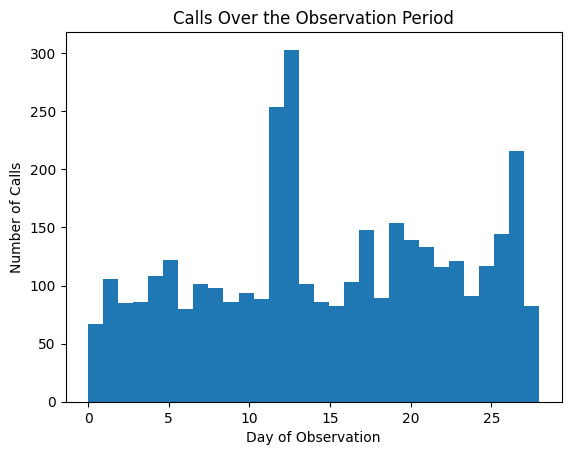

In [66]:
calls["day"] = calls["timestamp"] / (60 * 60 * 24)

plt.hist(calls["day"], bins=30)

plt.title("Calls Over the Observation Period")
plt.xlabel("Day of Observation")
plt.ylabel("Number of Calls")
plt.show()

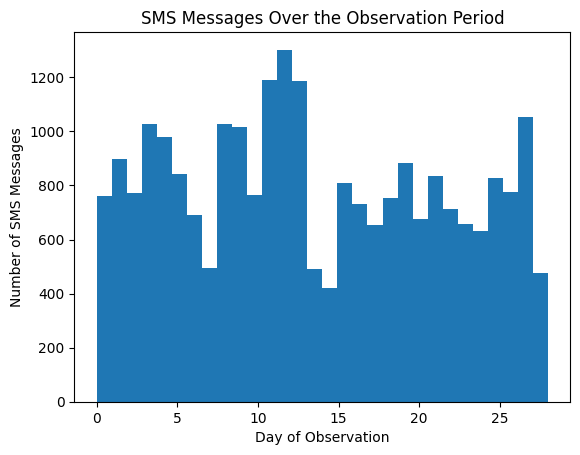

In [67]:
sms["day"] = sms["timestamp"] / (60 * 60 * 24)

plt.hist(sms["day"], bins=30)

plt.title("SMS Messages Over the Observation Period")
plt.xlabel("Day of Observation")
plt.ylabel("Number of SMS Messages")
plt.show()

In [68]:
print("DATA QUALITY SUMMARY")
print("--------------------")

print("Missing values in calls:", calls.isna().sum().sum())
print("Duplicate calls:", calls.duplicated().sum())

print("Durations below -1:", (calls["duration"] < -1).sum())

print("Bluetooth empty scans:", (bt["user_b"] == -1).sum())

print(
    "Bluetooth observations from devices outside experiment:",
    (bt["user_b"] == -2).sum()
)

DATA QUALITY SUMMARY
--------------------
Missing values in calls: 0
Duplicate calls: 0
Durations below -1: 0
Bluetooth empty scans: 2220136
Bluetooth observations from devices outside experiment: 827874


In [69]:

# Check overlap between users in the different datasets

call_users = set(calls["caller"]).union(set(calls["callee"]))
sms_users = set(sms["sender"]).union(set(sms["recipient"]))
bt_users = set(bt_participants["user_a"]).union(set(bt_participants["user_b"]))
gender_users = set(genders["user"])

print("Users in calls:", len(call_users))
print("Users in SMS:", len(sms_users))
print("Users in Bluetooth:", len(bt_users))
print("Users in gender data:", len(gender_users))

print("\nCall users also found in SMS:")
print(len(call_users.intersection(sms_users)))

print("\nCall users also found in Bluetooth:")
print(len(call_users.intersection(bt_users)))

print("\nCall users also found in gender data:")
print(len(call_users.intersection(gender_users)))

Users in calls: 536
Users in SMS: 568
Users in Bluetooth: 692
Users in gender data: 787

Call users also found in SMS:
496

Call users also found in Bluetooth:
493

Call users also found in gender data:
516


In [70]:
# Check the observation period in days

observation_days = (
    max(
        calls["timestamp"].max(),
        sms["timestamp"].max(),
        bt["timestamp"].max()
    )
    / (60 * 60 * 24)
)

print("Observation period:", round(observation_days, 2), "days")

Observation period: 28.0 days


In [71]:
print("Target distribution:")

target_distribution = (
    calls["answered"]
    .value_counts()
    .rename(index={0: "Missed", 1: "Answered"})
)

display(target_distribution)

print("\nTarget distribution (%):")

display(
    calls["answered"]
    .value_counts(normalize=True)
    .rename(index={0: "Missed", 1: "Answered"})
    .mul(100)
    .round(2)
)

Target distribution:


answered
Answered    3234
Missed       366
Name: count, dtype: int64


Target distribution (%):


answered
Answered    89.83
Missed      10.17
Name: proportion, dtype: float64